# 社交媒体用户表达与热浪

2022年四川热浪：从公众讨论、情感变化到空间差异。

<a id="course-toc"></a>
**目录**

- [1 研究概览](#section-1)
  - [1.1 背景：一次高温事件怎样影响城市生活？](#section-1-1)
  - [1.2 为什么研究：气温之外，还缺少什么？](#section-1-2)
  - [1.3 研究内容：要回答哪些问题？](#section-1-3)
  - [1.4 方法：从文本到时空证据](#section-1-4)
  - [1.5 结果：当前样本实际显示了什么？](#section-1-5)
  - [1.6 结果说明什么：关联、机制与证据边界](#section-1-6)
  - [1.7 结论：我们能回答到哪一步？](#section-1-7)
- [2 热相关筛选与多维影响标签](#section-2)
  - [2.1 人工核对：规则为什么会错？](#section-2-1)
  - [2.2 如何评价分类：先有独立真值](#section-2-2)
- [3 时间变化：数量与比例回答不同问题](#section-3)
  - [3.1 阶段比较：讨论结构有没有变化？](#section-3-1)
  - [3.2 同帖共现：一起被提到不等于因果传播](#section-3-2)
- [4 情感变化：日、阶段与相同用户](#section-4)
  - [4.1 先区分分类标签、概率与人的情绪](#section-4-1)
  - [4.2 Spearman：哪些讨论与模型分数同时变化？](#section-4-2)
  - [4.3 阶段检验：先说明什么是独立样本](#section-4-3)
  - [4.4 相同用户对照：构成变化会不会影响结论？](#section-4-4)
- [5 城市差异：讨论结构与城市画像](#section-5)
  - [5.1 城市数量、分母与解释](#section-5-1)
  - [5.2 K-means：不同城市能分成几类？](#section-5-2)
  - [5.3 行政边界图：把城市画像画在地图上](#section-5-3)
- [6 空间分布：把影响候选画回真实网格](#section-6)
  - [6.1 KDE：平滑会改变我们看到的热点吗？](#section-6-1)
    - [6.1.1 固定5公里带宽：米制计算的对照](#section-6-1-1)
- [7 气象背景：把城市日讨论与气温对齐](#section-7)
- [8 综合练习与解释](#section-8)
  - [8.1 改变分母](#section-8-1)
  - [8.2 检验词表敏感性](#section-8-2)
  - [8.3 开放问题：如何改进研究？](#section-8-3)
- [9 回到研究问题：结果、解释与结论](#section-9)

<a id="section-1"></a>
## 1 研究概览 **[重点]**

<a id="section-1-1"></a>
### 1.1 背景：一次高温事件怎样影响城市生活？

2022年夏季，四川盆地及长江流域经历持续高温与干旱。8月17日，中国气象局报告川渝多地超过40℃，并提示关注能源供应、人体健康、农业生产及气象干旱。热浪不仅意味着“天气热”，还可能与供水、供电、交通、生产和生态压力共同出现。[中国气象局当时的报告](https://www.cma.gov.cn/wmhd/2011wzbft/2011wftzb/202208/t20220817_5039002.html) [百度百科介绍](https://baike.baidu.com/item/2022%E5%B9%B4%E5%9B%9B%E5%B7%9D%E9%AB%98%E6%B8%A9%E4%BA%8B%E4%BB%B6/61926296)

本节以四川为研究区域，把微博看作公众表达的一个观察窗口。**研究的是热浪期间被记录的讨论，不把每条抱怨直接当作已经证实的灾损。** 事件背景来自独立资料；后面的14天样本不承担识别整次热浪起止的任务。

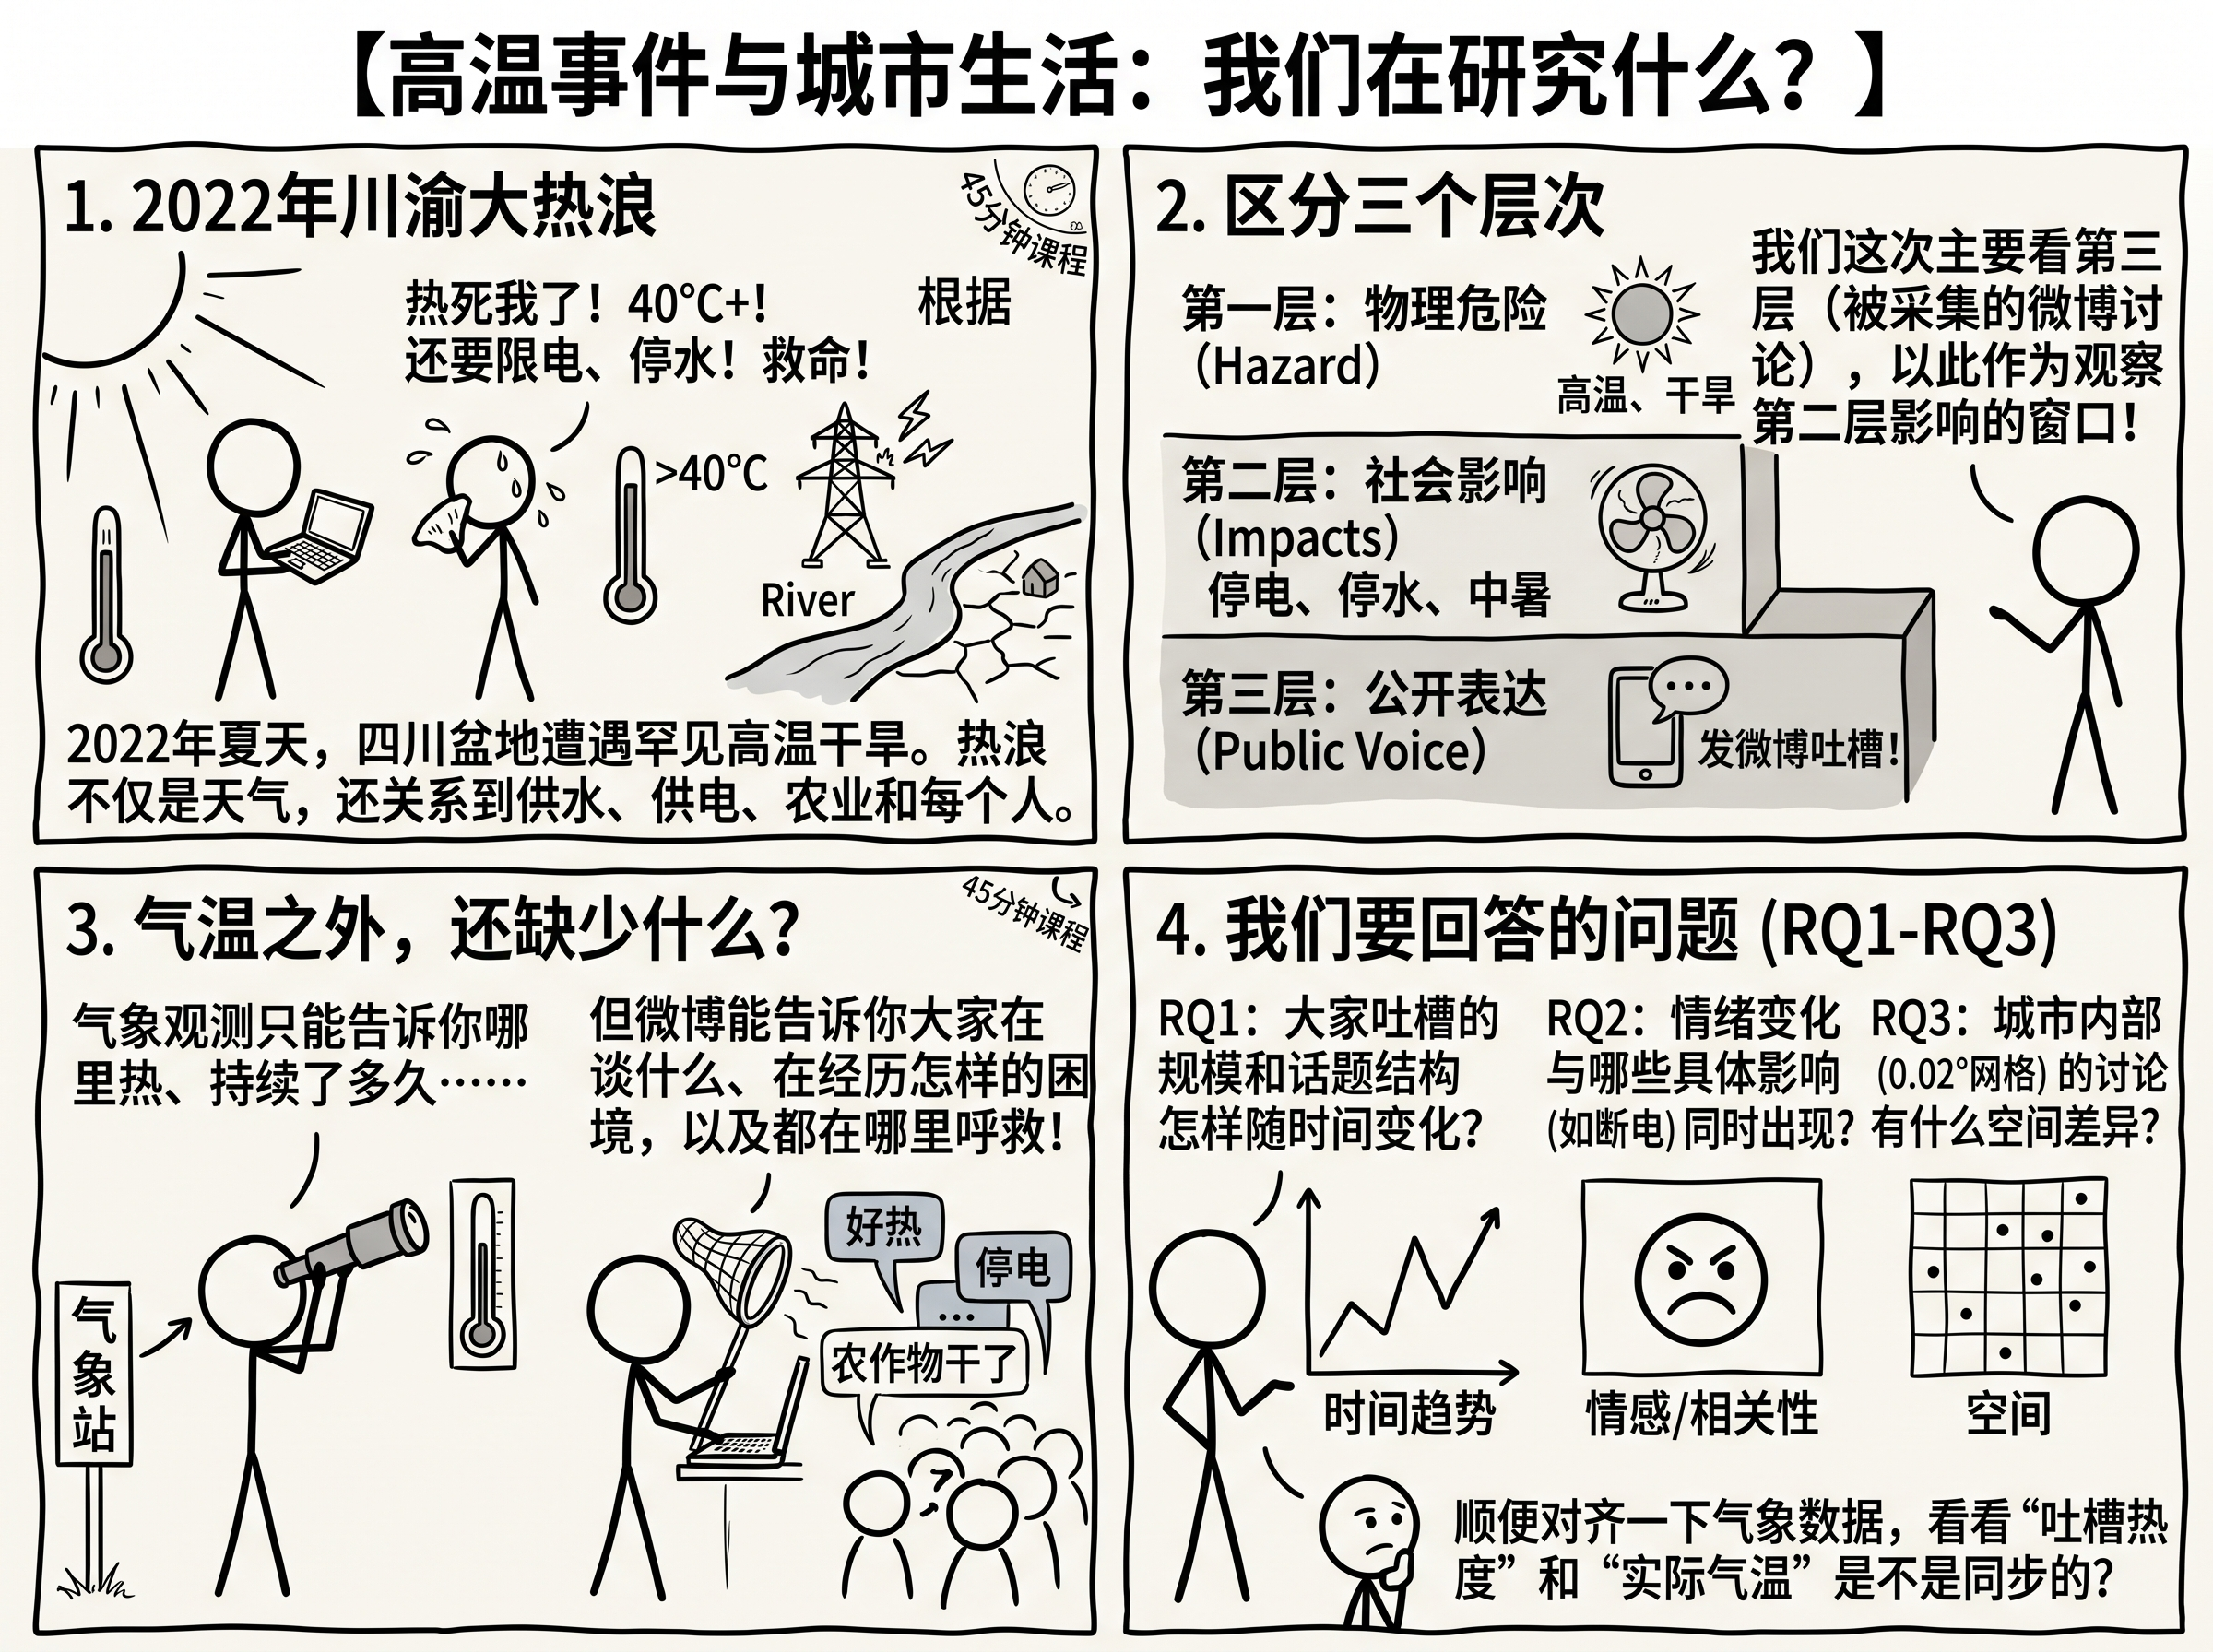

<a id="section-1-2"></a>
### 1.2 为什么研究：气温之外，还缺少什么？

气象观测告诉我们哪里热、持续多久；社交媒体可以补充人们在谈什么、表达怎样的感受，以及这些讨论出现在哪里。对城市治理而言，停电导致无法制冷、生产受限等生活经验值得与气象和设施记录一起观察。

需要区分三个层次：**物理危险（高温、干旱）→社会影响（服务与生活受到影响）→公开表达（被采集的帖子）**。本节主要观测第三层，通过文本候选讨论第二层；要验证完整传导链，还需要水文、电力、设施故障和调查等独立证据。

<a id="section-1-3"></a>
### 1.3 研究内容：要回答哪些问题？

| 研究问题 | 分析内容 | 对应章节 |
|---|---|---|
| RQ1：讨论规模与内容结构怎样变化？ | 热相关候选、五类影响、每日数量和比例、预设阶段比较、同帖共现 | 2—3 |
| RQ2：哪些影响讨论与情感变化同时出现？ | 模型分数与标签、帖子等权/用户等权、Spearman相关、阶段检验、相同用户比较 | 4 |
| RQ3：城市与城市内部的讨论是否相同？ | 城市比例与聚类、0.02°网格面、数量和比例、空间平滑 | 5—6 |
| 气象背景是否与讨论一致？ | 成都参考点气温与该城市日期对齐 | 7 |



<a id="section-1-4"></a>
### 1.4 方法：从文本到时空证据

分析流程是：**确定区域和日期 → 筛选热相关候选 → 标注多类影响讨论 → 检查情感字段 → 时间与空间汇总 → 核验和解释**。

| 环节 | 本节操作 | 需要检查什么？ |
|---|---|---|
| 数据范围 | 从课堂Parquet读取四川2022年8月12—25日的54,609条可用记录 | 区域、日期和采集覆盖是否与问题一致？ |
| 热相关筛选 | 用关键词建立候选集，再人工阅读命中与未命中的文本 | 是否误选或漏选？提到高温是否真的在讨论其影响？ |
| 影响标签 | 匹配健康、基础设施、交通、经济、生态五类词表；一帖可多类，未覆盖的热候选单列 | 每类标签的含义是否清楚？文本是否支持这个判断？ |
| 情感分析 | 使用已有模型标签与分数，比较帖子等权、用户等权和相同用户的结果 | 字段是否有效？权重和用户构成是否影响结果？ |
| 时间比较 | 比较每日数量、比例和预设阶段，计算Spearman相关并演示Mann–Whitney U检验 | 分母、阶段天数和日期之间的依赖是否影响解释？ |
| 空间比较 | 比较城市画像与聚类、0.02°网格比例，并用KDE观察四川候选位置的集中程度 | 数量与比例有何不同？小分母、投影和带宽是否影响图形？ |

本实验预先将8月17日设为阶段比较界点。数据仅覆盖两周，不能据此确定整次热浪的起止或恢复时间。关键词标签和情感模型输出都需要核验，不能直接当作灾损事实或人的真实心理状态。

<a id="section-1-5"></a>
### 1.5 结果：当前样本实际显示了什么？

下面先看默认词表、四川范围和两周日期下的**样本结果概览**，再通过后续代码逐步检查。修改词表、日期或分母后，以重新运行的表和图为准：

| 结果 | 计算值 | 读法 |
|---|---|---|
| 热相关候选 | 3,541 / 54,609条，约6.48% | 是规则候选率，不是已验证的热浪受害比例 |
| 阶段候选比例 | 前期4.09%，后期7.82% | 分母分别是各阶段全部可用记录 |
| 基础设施候选占热候选 | 前期23.8%，后期55.0% | 讨论结构发生变化；词表中的“空调”等仍可能误选 |
| 基础设施日计数与日均正向模型分数 | Spearman ρ约−0.675，14个日期 | 负向关联；不能解释成基础设施造成情感变化的因果效应 |
| 城市与同用户覆盖 | 20城达到20条热候选门槛；配对用户仅13位 | 小分母和筛选会改变代表性 |

第9节再次用当前变量汇总结果，便于检查这份概览与实际运行是否一致。

<a id="section-1-6"></a>
### 1.6 结果说明什么：关联、机制与证据边界

讨论比例与结构的变化提示，观察热浪时应同时关注生活服务和公众表达，不能只盯着最高气温。城市间的差异可以帮助提出进一步核验的问题，例如某地基础设施讨论较多，是否与真实停电记录相符？

这些证据仍有边界：候选标签不是灾损事实；城市讨论比例不是人口脆弱性；相关系数不是机制证明；模型分数不是心理健康量表。两个阶段的日数为5和9，不能直接比较累计条数；样本只覆盖两周，不能判断这些变化在之后是否持续或恢复。

<a id="section-1-7"></a>
### 1.7 结论：我们能回答到哪一步？

当前样本支持的结论是：**在这两周的四川微博记录中，热相关候选的讨论比例和内容结构发生变化，基础设施候选讨论与日均正向模型分数呈负向关联，不同城市和网格的表达分布也不相同。**



In [ ]:
# 保持整个tutorials文件夹结构；支持从项目根目录或tutorials目录启动。
from pathlib import Path
TUTORIAL_DIR = Path('.') if Path('data/posts_two_weeks.parquet').is_file() else Path('tutorials')
DATA = TUTORIAL_DIR / 'data/posts_two_weeks.parquet'
assert DATA.is_file(), '请先完整解压课堂资料，并用VS Code打开包含tutorials的文件夹'

In [ ]:
# 需要读表时再导入Pandas；研究范围与02、04相同。
import pandas as pd
columns = ['post_id', 'user_id', 'date', 'city_code', 'city', 'text',
           'sentiment_label_source', 'sentiment_score_0_source', 'sentiment_score_1_source',
           'score_valid', 'longitude_grid', 'latitude_grid', 'coordinate_valid']
posts = pd.read_parquet(DATA, columns=columns,
                       filters=[('province_code', '==', '51'), ('usable_text', '==', True)])
posts['date'] = pd.to_datetime(posts['date'])
print('记录：', len(posts), '用户：', posts['user_id'].nunique(), '日期：', posts['date'].nunique())
posts[['date', 'city', 'text']].head()

<a id="section-2"></a>
## 2 热相关筛选与多维影响标签 **[重点]**

关键词规则适合快速建立候选集，并逐条检查。它不理解否定、讽刺和因果：提到“停电”不一定是高温导致，提到“热”也可能在说热搜。这里的标签都叫**候选讨论**。

先筛热相关候选，再匹配五类词表。规则可能漏掉没有热词但确实相关的帖子，也可能误选。未命中五类的热候选记为“其他/未覆盖”，不能理解为已完成语义判断。

In [ ]:
# 用明确的短词组减少“热搜”等歧义，但仍需人工核对。
heat_words = ['高温', '热浪', '炎热', '闷热', '酷暑', '热死', '太热', '中暑', '避暑', '限电', '停电', '干旱']
# re.escape把词条当成普通文本；|表示匹配任意一个词条。
import re
heat_pattern = '|'.join(re.escape(word) for word in heat_words)
posts['heat_candidate'] = posts['text'].str.contains(heat_pattern, regex=True, na=False)
impact_words = {
    '健康': ['中暑', '热射病', '脱水', '头晕', '晒伤', '失眠', '难受', '热死'],
    '基础设施': ['停电', '限电', '断电', '电力', '供电', '停水', '缺水', '空调'],
    '交通': ['地铁', '公交', '铁路', '高铁', '停运', '延误', '航班'],
    '经济': ['停产', '工厂', '生产', '营业', '商场', '停工', '放假', '办公'],
    '生态': ['干旱', '旱灾', '河流', '水库', '森林', '山火', '农作物', '庄稼']}
# 每次只增加一列布尔标签：先热候选，再匹配该类词表。
for name, words in impact_words.items():
    pattern = '|'.join(re.escape(word) for word in words)
    posts[name] = posts['heat_candidate'] & posts['text'].str.contains(pattern, na=False)
categories = list(impact_words)
posts['其他/未覆盖'] = posts['heat_candidate'] & posts[categories].sum(axis=1).eq(0)
posts.loc[posts['heat_candidate'], ['text', *categories, '其他/未覆盖']].head(8)

<a id="section-2-1"></a>
### 2.1 人工核对：规则为什么会错？

先读候选文本，再读少量未命中文本，检查误选和漏选。下面的标注列留空，由阅读者判断，不能把规则标签直接当成人工真值。对真实文本的判断要说明依据，转发、新闻和个人经历也应区分。

模型扩展可以沿用02的BERTopic或预训练情感分类，但主题发现不是影响分类；没有经过验证的模型标签不能自动替代人工核对。完整模型流程需要独立标注集、评估和误差分析。

In [ ]:
# 各抽6条命中和未命中记录；保留post_id用于核对，展示时不列出用户ID。
audit = posts.groupby('heat_candidate', group_keys=False).sample(n=6, random_state=42)
audit = audit[['post_id', 'date', 'text', 'heat_candidate', *categories]].copy()
# 人工真值由阅读后填写，不能直接复制规则结果。
audit['human_heat'] = pd.NA
for name in categories:
    audit['human_' + name] = pd.NA
audit['evidence'] = ''
audit[['date', 'text', 'heat_candidate', 'human_heat', 'evidence']]

<a id="section-2-2"></a>
### 2.2 如何评价分类：先有独立真值 **[扩展]**

精确率Precision回答“判为相关的，有多少真的相关”；召回率Recall回答“真正相关的，有多少被找出”；F1折中两者。每个影响类别也要分别评价，不能只报一个总准确率。

人工列填写0或1（否/是），`evidence`填写原文依据，拿不准时留空。下面仅在手工填写`audit`真值后，评价**当前规则基线**。12条按命中与否分层抽样的例子用于理解错误，不能代表总体准确率；正式研究应另建有抽样设计的独立测试集。

In [ ]:
# 只有真实填写了人工判断才计算，不把缺失真值当成0。
from sklearn.metrics import precision_recall_fscore_support
checks = [('热相关', 'human_heat', 'heat_candidate')]
checks += [(name, 'human_' + name, name) for name in categories]
evaluation_rows = []
for name, truth, prediction in checks:
    checked = audit.dropna(subset=[truth])
    if len(checked):
        precision, recall, f1, _ = precision_recall_fscore_support(
            checked[truth].astype(int), checked[prediction].astype(int),
            average='binary', zero_division=0)
        evaluation_rows.append({'任务': name, '人工标注数': len(checked),
                                'precision': precision, 'recall': recall, 'F1': f1})
if not evaluation_rows:
    print('尚未填写人工真值，不能报告分类性能。')
pd.DataFrame(evaluation_rows, columns=['任务', '人工标注数', 'precision', 'recall', 'F1'])

<a id="section-3"></a>
## 3 时间变化：数量与比例回答不同问题 **[重点]**

每天总记录量不同，单看候选条数可能把采集量变化误读成讨论变化。热候选比例的分母是当天全部可用记录；各影响类别的条件比例，分母是当天热候选记录。

一帖可命中多类，所以各类比例之和可以超过100%。某日没有热候选时，条件比例应缺失，不能填成0来表示“无人讨论”。

In [ ]:
# size数全部记录，sum数布尔命中；两种计数有不同含义。
daily = posts.groupby('date').agg(n_posts=('post_id', 'size'),
    n_users=('user_id', 'nunique'), heat_posts=('heat_candidate', 'sum'))
daily['heat_share'] = daily['heat_posts'] / daily['n_posts']
impact_daily = posts.groupby('date')[categories].sum()
# where让0分母变成缺失；div按日期行对齐分母。
impact_share = impact_daily.div(daily['heat_posts'].where(daily['heat_posts'].gt(0)), axis=0)
daily

In [ ]:
# 第一次画图时再导入Plotly；图形可以缩放、悬停和开关图例。
import plotly.express as px
import plotly.io as pio
pio.renderers.default = 'plotly_mimetype+notebook'
px.defaults.template = 'simple_white'

In [ ]:
# 先展示热候选占全部记录的比例，悬停时同时看两种计数。
fig = px.line(daily.reset_index(), x='date', y='heat_share', markers=True,
    hover_data=['n_posts', 'heat_posts', 'n_users'],
    labels={'date': '日期', 'heat_share': '热候选 / 当日全部记录'}, title='四川两周的热候选讨论比例')
fig.update_yaxes(tickformat='.0%')
fig

In [ ]:
# melt把多列类别转成长表，便于同一张图画多条线。
impact_long = impact_share.reset_index().melt(id_vars='date', var_name='类别', value_name='条件比例')
fig = px.line(impact_long, x='date', y='条件比例', color='类别', markers=True,
    labels={'date': '日期'}, title='各类影响候选 / 当日热候选记录（一帖可多类）')
fig.update_yaxes(tickformat='.0%')
fig

<a id="section-3-1"></a>
### 3.1 阶段比较：讨论结构有没有变化？ **[重点]**

8月12—16日为前期（5天），17—25日为后期（9天）。8月17日是本实验在比较前设定的界点，不是从结果中挑选的“最佳转折点”。分别比较阶段内的比例与日均数，不把日数较长的累计数量直接当成强度增加。

下表的类别比例按**阶段总命中数 / 阶段热候选数**计算；它不同于先求每日比例再平均。可思考：改变界点、词表和分母后，方向是否仍成立？

In [ ]:
# 在需要分阶段时才创建phase；顺序也供后面的图表使用。
phase_order = ['前期', '后期']
posts['phase'] = posts['date'].lt('2022-08-17').map({True: '前期', False: '后期'})
phase_summary = posts.groupby('phase').agg(n_days=('date', 'nunique'),
    n_posts=('post_id', 'size'), heat_posts=('heat_candidate', 'sum')).reindex(phase_order)
phase_summary['heat_share'] = phase_summary['heat_posts'] / phase_summary['n_posts']
phase_summary['heat_per_day'] = phase_summary['heat_posts'] / phase_summary['n_days']
phase_impacts = posts.groupby('phase')[categories].sum().reindex(phase_order)
phase_impact_share = phase_impacts.div(phase_summary['heat_posts'], axis=0)
phase_summary.join(phase_impact_share.add_suffix('_占热候选'))

In [ ]:
# 分组柱形图分别画每个标签；多标签比例不堆叠成总和100%。
phase_long = phase_impact_share.reset_index().melt(id_vars='phase',
    var_name='类别', value_name='比例')
fig = px.bar(phase_long, x='类别', y='比例', color='phase', barmode='group',
    category_orders={'phase': phase_order}, labels={'phase': '阶段'},
    title='两个阶段的讨论结构（每类候选 / 本阶段热候选）')
fig.update_yaxes(tickformat='.0%')
fig

默认样本中，基础设施候选比例由约23.8%升到55.0%；健康候选由约12.2%变为10.8%。前者是结构变化的线索，后者不表示健康影响减轻：比例会随其他类别和总体候选量变化。先核对文本，再与真实事件记录对照。

<a id="section-3-2"></a>
### 3.2 同帖共现：一起被提到不等于因果传播

把布尔标签转成0/1，`标签表.T @ 标签表`得到共现计数。对角线是每类命中数，其他格子是一帖同时命中两类的次数。

健康与基础设施共现，可能来自个人体验、新闻转发或词表误选。要判断停电是否影响健康，还需要语义核验、时间关系与外部记录。

In [ ]:
# @是矩阵乘法；一次累加所有帖子的标签组合。
labels = posts.loc[posts['heat_candidate'], categories].astype(int)
cooccurrence = labels.T @ labels
fig = px.imshow(cooccurrence, text_auto=True, color_continuous_scale='Blues',
                title='同一帖子中的候选标签共现次数')
fig

<a id="section-4"></a>
## 4 情感变化：日、阶段与相同用户 **[重点]**

<a id="section-4-1"></a>
### 4.1 先区分分类标签、概率与人的情绪

源字段按0=负向、1=正向解释；`sentiment_score_1_source`是模型对“正向”类别的分数。0.8不是“80%的幸福程度”。概率范围、两类和为1、标签与最大分数一致，只能检查内部一致性，不能验证语义准确率或校准。

本节情感分析统一先取**有效情感的热相关候选**。每日帖子等权让每条帖子贡献一次；用户等权先求每位用户当天平均分，再对用户求平均。两种权重都不保证代表所有居民。

In [ ]:
# 先检查原始分数字段，再取有效的热候选；不覆盖源模型输出。
source_scores = posts.loc[posts['score_valid']]
score_check = pd.Series({
    '有效记录数': len(source_scores),
    '概率和接近1的比例': (source_scores['sentiment_score_0_source'] +
                         source_scores['sentiment_score_1_source'] - 1).abs().lt(1e-5).mean(),
    '标签与最大分数一致比例': source_scores['sentiment_label_source'].eq(
        source_scores['sentiment_score_1_source'].gt(source_scores['sentiment_score_0_source']).astype(int)).mean()
})
sent = posts.loc[posts['heat_candidate'] & posts['score_valid'] &
                 posts['sentiment_label_source'].isin([0, 1])].copy()
sent['negative'] = sent['sentiment_label_source'].eq(0)
print('热候选中的负向标签比例：', f"{sent['negative'].mean():.1%}")
score_check

In [ ]:
# 一行一个日期；同一天发得更多的用户，在user_equal中仍只贡献一个日均值。
sentiment_daily = sent.groupby('date').agg(n_scored=('post_id', 'size'),
    n_users=('user_id', 'nunique'), post_equal=('sentiment_score_1_source', 'mean'),
    negative_share=('negative', 'mean'))
user_day_score = sent.groupby(['date', 'user_id'])['sentiment_score_1_source'].mean()
sentiment_daily['user_equal'] = user_day_score.groupby('date').mean()
score_long = sentiment_daily[['post_equal', 'user_equal']].reset_index().melt(
    id_vars='date', var_name='权重', value_name='平均正向分数')
fig = px.line(score_long, x='date', y='平均正向分数', color='权重', markers=True,
    labels={'date': '日期'}, title='热候选文本的日均模型分数：两种权重')
fig.add_vline(x=pd.Timestamp('2022-08-17').timestamp()*1000, line_dash='dash')
fig

<a id="section-4-2"></a>
### 4.2 Spearman：哪些讨论与模型分数同时变化？ **[重点]**

Spearman相关衡量两列数值的**单调关联**，范围为−1到1。本节一行一个日期，因此有效样本量是配对日期数，最多14，不是3,541条帖子。

对每一类分别比较：①当日候选数量与当日帖子等权平均正向分数；②该类占当日热候选的比例与同一分数。它们回答不同问题，数量还受采集量影响。共同趋势、事件、时间自相关及词表误差都可能产生关联；这里不把普通相关检验的p值当作时间序列的可靠推断。

In [ ]:
# corr按日期索引自动对齐；先数有效的成对日期，再计算rho。
correlations = pd.DataFrame({
    'count_rho': impact_daily.corrwith(sentiment_daily['post_equal'], method='spearman'),
    'share_rho': impact_share.corrwith(sentiment_daily['post_equal'], method='spearman')
})
correlations['n_dates_count'] = impact_daily.apply(lambda x:
    (x.notna() & sentiment_daily['post_equal'].reindex(x.index).notna()).sum())
correlations['n_dates_share'] = impact_share.apply(lambda x:
    (x.notna() & sentiment_daily['post_equal'].reindex(x.index).notna()).sum())
correlations

In [ ]:
# 负值表示候选讨论较多（或占比更高）的日期，正向模型分数往往更低。
corr_long = correlations.reset_index(names='类别').melt(id_vars='类别',
    value_vars=['count_rho', 'share_rho'], var_name='口径', value_name='Spearman ρ')
fig = px.bar(corr_long, x='类别', y='Spearman ρ', color='口径', barmode='group',
    title='影响候选与每日平均正向模型分数的相关（14个日期）')
fig.update_yaxes(range=[-1, 1])
fig

默认结果中，基础设施的计数ρ约−0.675、比例ρ约−0.780。与健康等类别的差异值得检查，但不能把“绝对值更大”写成已经证明的驱动机制。分类规则、样本构成、新闻转发和同日事件都可能影响结果。

<a id="section-4-3"></a>
### 4.3 阶段检验：先说明什么是独立样本 **[扩展]**

使用Mann–Whitney U比较阶段情感分布。它不要求正态分布，但要求两组独立样本；也不是在任何情况下都只检验中位数。

这里仅演示**5个前期日均值与9个后期日均值**的计算。先报告均值、差值和样本数，再看U与p。时间相邻的日期可能不独立，因此下面的p是忽略时间依赖时的参考计算，不能直接支撑正式显著性结论。恢复期数据缺失时不补值，也不执行恢复期检验。[SciPy方法说明](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html)

In [ ]:
# 在使用检验时才导入；每个观测是一个日期，不把每条帖子当成独立重复。
from scipy.stats import mannwhitneyu
before = sentiment_daily.loc[sentiment_daily.index < '2022-08-17', 'post_equal'].dropna()
after = sentiment_daily.loc[sentiment_daily.index >= '2022-08-17', 'post_equal'].dropna()
test = mannwhitneyu(before, after, alternative='two-sided', method='auto')
phase_test = pd.Series({'前期日数': len(before), '后期日数': len(after),
    '前期日均分的均值': before.mean(), '后期日均分的均值': after.mean(),
    '后期减前期': after.mean()-before.mean(), 'U_以前期为第一组': test.statistic,
    'p_忽略时间依赖的参考值': test.pvalue})
phase_test

默认两段日均正向分数约为0.735与0.696，参考p约0.060。应同时报告差值、样本数和检验假设，不为了得到较小的p值而反复调整阶段划分；“未达到某阈值”也不等于已经证明没有差异。更可靠的判断还需要更长时段、对时间依赖的处理，以及文本标签的验证。

<a id="section-4-4"></a>
### 4.4 相同用户对照：构成变化会不会影响结论？ **[扩展]**

源字段按0=负向、1=正向解释；这里使用已有的二分类标签，仅保留`score_valid`为真的记录。它衡量模型对文本的分类，不是心理健康、幸福感或抑郁测量；模型误差仍需验证。

先在热候选中按“用户×时期”汇总。只保留两个时期各至少2条有效情感记录的相同用户，再计算每人的负向比例差。前期为8月12—16日，后期为8月17—25日，两段长度不同；该比较不是因果识别。

In [ ]:
# 筛选之后复制，避免修改原始posts表。
sent = posts.loc[posts['heat_candidate'] & posts['score_valid'] &
                 posts['sentiment_label_source'].isin([0, 1])].copy()
sent['negative'] = sent['sentiment_label_source'].eq(0)
sent['phase'] = sent['date'].lt('2022-08-17').map({True: '前期', False: '后期'})
user_phase = sent.groupby(['user_id', 'phase']).agg(
    n_posts=('post_id', 'size'), negative_share=('negative', 'mean'))
# 先按分母筛选，再转成一行一用户、两列两时期的配对表。
paired = user_phase.loc[user_phase['n_posts'].ge(2), 'negative_share'].unstack('phase').dropna()
paired['后期减前期'] = paired['后期'] - paired['前期']
print('两个时期均符合条件的用户数：', len(paired))
paired[['前期', '后期', '后期减前期']].describe()

In [ ]:
# 每个用户贡献一个差值；0表示这位用户的负向比例没有变化。
fig = px.histogram(paired, x='后期减前期', nbins=15,
    labels={'count': '用户数'}, title='相同用户的负向表达比例变化（候选样本）')
fig.add_vline(x=0, line_dash='dash')
fig

仅13位用户在两个阶段各有至少2条有效候选记录。这个筛选控制了一部分用户构成变化，却得到很小且偏向高频发帖者的样本。默认差值的中位数为0，不能据少量用户的平均变化推广到全体用户。

<a id="section-5"></a>
## 5 城市差异：讨论结构与城市画像 **[重点]**

以城市热候选数为分母，比较五类候选讨论比例。只展示热候选至少20条的城市，并把分母一起展示。城市编码来自原数据，不由点落在哪个行政边界重新推定。

城市比例描述被采集到的讨论结构，不能直接解释人口风险、基础设施故障率或城市脆弱性。

In [ ]:
# 先计城市分母，再按相同城市索引计算类别比例。
heat = posts.loc[posts['heat_candidate']].copy()
city_n = heat.groupby('city').size().rename('heat_posts')
city_share = heat.groupby('city')[categories].sum().div(city_n, axis=0)
city_share = city_share.loc[city_n.ge(20)]
city_summary = city_share.join(city_n)
city_summary.sort_values('heat_posts', ascending=False)

In [ ]:
# 城市×类别的热图保留全部合格城市；颜色表示比例，不是条数。
fig = px.imshow(city_share, aspect='auto', text_auto='.0%',
    color_continuous_scale='YlOrRd', zmin=0, zmax=1,
    labels={'x': '候选类别', 'y': '原数据城市标签', 'color': '比例'},
    title='各城市候选讨论结构（分母为该城热候选记录）')
fig

<a id="section-5-1"></a>
### 5.1 城市数量、分母与解释

原数据中的21个城市标签里，本词表下20城达到至少20条热候选的门槛。成都的候选数量最多；它的候选占比与其他城市的占比仍须按各自分母计算，不能把数量优势直接称作风险最高。

城市画像使用五类候选占本城热候选的比例。这个分母与“本城全部可用记录”“人口”不同；报告任何城市排名时都要写清楚分母，并检查20条门槛和词表是否改变排序。

<a id="section-5-2"></a>
### 5.2 K-means：不同城市能分成几类？ **[扩展]**

每座合格城市是一个样本，五类比例是五个特征。先做Z-score标准化，再比较k=2—7的组内平方和（inertia）和轮廓系数（silhouette）。轮廓系数衡量同簇是否更近，较高只表示当前特征下的分组相对清晰，不等于真实城市类型。

下面按当前最大轮廓系数选择候选k，并检查更换随机种子后分组是否改变。还要查看每类的成员、原始比例和样本量，判断分组能否帮助理解城市差异；聚类数应根据当前特征与数据选择。

In [ ]:
# 在需要聚类时再导入；标准化不会消除小分母与词表误差。
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
X = StandardScaler().fit_transform(city_share)
choices = []
for k in range(2, 8):
    model = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    choices.append({'k': k, 'silhouette': silhouette_score(X, model.labels_),
                    'inertia': model.inertia_})
cluster_choices = pd.DataFrame(choices)
cluster_choices

In [ ]:
# 最大轮廓系数只提供候选选择，还要读各类原始比例和小分母。
chosen_k = int(cluster_choices.loc[cluster_choices['silhouette'].idxmax(), 'k'])
model = KMeans(n_clusters=chosen_k, n_init=20, random_state=42).fit(X)
second_model = KMeans(n_clusters=chosen_k, n_init=20, random_state=7).fit(X)
city_clusters = city_summary.assign(cluster=model.labels_)
print('当前候选k：', chosen_k, '；换随机种子的ARI：',
      round(adjusted_rand_score(model.labels_, second_model.labels_), 3))
# ARI比较分组是否相同，不受簇编号顺序变化影响；不代表换词表也稳定。
cluster_profiles = city_clusters.groupby('cluster')[categories].mean()
fig = px.imshow(cluster_profiles, text_auto='.0%', aspect='auto', zmin=0, zmax=1,
    labels={'x': '候选类别', 'y': '簇号', 'color': '城市平均比例'},
    title='每一簇的城市画像（各城市等权；簇号没有风险顺序）')
fig

In [ ]:
# 与簇均值一起看成员和分母，再判断分组有没有解释价值。
city_clusters.sort_values(['cluster', 'heat_posts'], ascending=[True, False])

<a id="section-5-3"></a>
### 5.3 行政边界图：把城市画像画在地图上 **[重点]**

从六位边界`adcode`取前四位，与本数据四位`city_code`对应；不要直接拿英文城市名与中文边界名连接。统计继续沿用原记录城市字段，不依据粗网格中心重新归属。

21个市州的边界全部保留；未达到20条热候选门槛的城市用灰色表示“不展示比例”，不是0影响。地图默认画基础设施候选占该城热候选的比例，结合上面的城市表同时查看分母。

In [ ]:
# 首次使用边界时读取缓存；DataV为GCJ-02，清除读取器默认的4326标签。
import geopandas as gpd
BOUNDARY_DIR = TUTORIAL_DIR / 'data/spatial/boundaries'
city_boundaries = gpd.read_file(BOUNDARY_DIR / 'sichuan_cities_gcj02.geojson').set_crs(None, allow_override=True)
city_boundaries = city_boundaries[['adcode', 'name', 'geometry']].copy()
city_boundaries.geometry = city_boundaries.geometry.make_valid(method='structure', keep_collapsed=False)
city_boundaries['city_code'] = city_boundaries['adcode'].astype(str).str[:4]
# 每个源城市名必须对应一个city_code，才能安全连接画像。
city_codes = posts[['city', 'city_code']].drop_duplicates()
assert city_codes['city'].is_unique and city_codes['city_code'].is_unique
city_stats = city_summary.reset_index().merge(city_codes, on='city', validate='one_to_one')
city_map_data = city_boundaries.merge(city_stats, on='city_code', how='left', validate='one_to_one')
city_map_data[['adcode', 'name', 'heat_posts', *categories]]

GeoPlot基于Matplotlib和Cartopy绘制静态地图：`polyplot()`画行政边界，`choropleth()`按数值或类别给面着色，后面的`kdeplot()`用于观察点的空间集中。`ax`表示同一张图的绘图区，后续图层传入同一个`ax`就能叠加。

GeoPlot的地理输入使用经纬度。下面将GCJ-02边界近似转换为WGS84显示副本，再用`AlbersEqualArea()`等积投影绘图；原始边界、城市归属和统计值保持不变。不加载网络底图，沿用04的轻微XKCD线条与中文字体。灰色表示未达到展示门槛，不代表0影响。

In [ ]:
# 需要绘制空间地图时再导入；GeoPlot绘图最终显示为静态图片。
import geoplot as gplt
import geoplot.crs as gcrs
import matplotlib.pyplot as plt
import shapely
from xyconvert import gcj2wgs

plt.xkcd(scale=0.5)  # 手绘线条只改变样式，不改变数值和几何坐标。
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [
    'Microsoft YaHei', 'PingFang SC', 'Noto Sans CJK SC', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['font.size'] = 11
plt.rcParams['axes.unicode_minus'] = False

# transform逐个转换顶点，并保留多边形的孔洞和多个组成部分。
city_wgs = city_map_data.copy()
city_wgs.geometry = shapely.transform(city_wgs.geometry.array, gcj2wgs)
city_wgs = city_wgs.set_crs('EPSG:4326')  # 转换数值之后，才声明WGS84。
sichuan_extent = tuple(city_wgs.total_bounds)  # 后续地图统一保留四川完整范围。


In [ ]:
# 类别放在绘图处设置；可改为健康、交通、经济或生态。
CITY_CATEGORY = '基础设施'
from matplotlib.ticker import PercentFormatter
# 先画全部21个市州；未达门槛的城市保留灰色底。
ax = gplt.polyplot(city_wgs, projection=gcrs.AlbersEqualArea(),
    facecolor='#bdbdbd', edgecolor='#555555', linewidth=0.6, figsize=(10, 7))
# hue选择着色字段，norm统一0—1色阶，dropna仅控制哪些城市叠加颜色。
gplt.choropleth(city_wgs.dropna(subset=[CITY_CATEGORY]), ax=ax,
    extent=sichuan_extent, hue=CITY_CATEGORY, cmap='YlOrRd', norm=plt.Normalize(0, 1),
    edgecolor='#555555', linewidth=0.6, legend=True,
    legend_kwargs={'label': CITY_CATEGORY+'候选 / 本城热候选',
                   'format': PercentFormatter(1), 'shrink': 0.7})
ax.set_title(CITY_CATEGORY+'候选占本城热候选的比例\n灰色：未达展示门槛')
ax.set_axis_off()
plt.show()


In [ ]:
# 保留原始GCJ-02统计表；显示时借用已经转换好的WGS84城市边界。
cluster_stats = city_clusters.reset_index().merge(city_codes, on='city', validate='one_to_one')
cluster_map_data = city_boundaries.merge(cluster_stats[['city_code', 'cluster']], on='city_code', how='left')
cluster_map_data['cluster_label'] = cluster_map_data['cluster'].map(
    lambda value: None if pd.isna(value) else '簇'+str(int(value)))
cluster_wgs = city_wgs[['city_code', 'geometry']].merge(
    cluster_map_data[['city_code', 'cluster_label']], on='city_code', validate='one_to_one')

ax = gplt.polyplot(cluster_wgs, projection=gcrs.AlbersEqualArea(),
    facecolor='#bdbdbd', edgecolor='#555555', linewidth=0.6, figsize=(10, 7))
# 使用Set2的前k种颜色，避开其中的灰色，让它与‘未达门槛’明确区分。
from matplotlib.colors import ListedColormap
cluster_colors = ListedColormap(plt.get_cmap('Set2').colors[:chosen_k])
# categorical明确按类别着色；簇号没有风险高低顺序。
gplt.choropleth(cluster_wgs.dropna(subset=['cluster_label']), ax=ax,
    extent=sichuan_extent, hue='cluster_label', scheme='categorical', cmap=cluster_colors,
    edgecolor='#555555', linewidth=0.6, legend=True,
    legend_kwargs={'title': '城市画像类别', 'loc': 'upper left', 'bbox_to_anchor': (1, 1)})
ax.set_title('城市画像聚类：簇号不代表风险顺序\n灰色：未达展示门槛')
ax.set_axis_off()
plt.show()


边界来源为[DataV.GeoAtlas](https://datav.aliyun.com/portal/school/atlas/atlas_aigc)，缓存信息见`data/spatial/boundaries/provenance.json`；这是教学边界快照，不将下载日期解释为边界的生效日期。

<a id="section-6"></a>
## 6 空间分布：把影响候选画回真实网格 **[重点]**

城市表会遮住城市内部差异。延续04，把0.02°中心重建成网格面，同时保留每格的总记录数、用户数和影响候选数。这里选择“基础设施”作示例，可改成其他类别。

**数量多**与**占比较高**是不同问题。候选占比的分母是格内全部可用位置记录；小分母的100%不一定比大样本的20%更可靠。没有观测记录的地方留空，不当作0影响。

源网格与DataV边界均为GCJ-02。统计保留原始网格；GeoPlot绘图使用近似转换后的WGS84几何副本，米制KDE再将同一副本投影到米制坐标，不对原始数据重复偏移。放大0.02°网格不能获得更高精度。

In [ ]:
# 参数放在使用处；可改成健康、交通、经济或生态，再重跑本节。
MAP_CATEGORY = '基础设施'
spatial_posts = posts.loc[posts['coordinate_valid']].copy()
grid_summary = spatial_posts.groupby(['longitude_grid', 'latitude_grid']).agg(
    n_posts=('post_id', 'size'), n_users=('user_id', 'nunique'),
    n_hits=(MAP_CATEGORY, 'sum')).reset_index()
grid_summary['hit_share'] = grid_summary['n_hits'] / grid_summary['n_posts']
# 与04一致，中心±0.01度重建网格；原始精确位置无法恢复。
import geopandas as gpd
import shapely
grid_geo = gpd.GeoDataFrame(grid_summary, geometry=shapely.box(
    grid_summary['longitude_grid']-0.01, grid_summary['latitude_grid']-0.01,
    grid_summary['longitude_grid']+0.01, grid_summary['latitude_grid']+0.01), crs=None)
print('有观测的网格数：', len(grid_geo), '；该类候选数：', int(grid_geo['n_hits'].sum()))
grid_geo[['n_posts', 'n_users', 'n_hits', 'hit_share']].describe()

In [ ]:
# 原始网格统计保持GCJ-02；仅转换需要显示的几何副本。
map_cells = grid_geo.copy()
visible_cells = map_cells.loc[map_cells['n_posts'].ge(5)]  # 小分母网格不画比例。
grid_wgs = visible_cells.copy()
grid_wgs.geometry = shapely.transform(grid_wgs.geometry.array, gcj2wgs)
grid_wgs = grid_wgs.set_crs('EPSG:4326')

ax = gplt.choropleth(grid_wgs, projection=gcrs.AlbersEqualArea(),
    extent=sichuan_extent, hue='hit_share', cmap='YlOrRd', norm=plt.Normalize(0, 1),
    edgecolor='#555555', linewidth=0.2, legend=True, figsize=(10, 7),
    legend_kwargs={'label': MAP_CATEGORY+'候选 / 格内可用位置记录',
                   'format': PercentFormatter(1), 'shrink': 0.7})
# 传入同一个ax叠加轮廓；行政范围不等于已观测范围。
gplt.polyplot(city_wgs, ax=ax, extent=sichuan_extent,
    edgecolor='#163d59', facecolor='none', linewidth=0.7, zorder=2)
ax.set_title(MAP_CATEGORY+'候选的网格比例（0.02°；至少5条记录）')
ax.set_axis_off()
plt.show()


<a id="section-6-1"></a>
### 6.1 KDE：平滑会改变我们看到的热点吗？ **[扩展]**

核密度估计（KDE）在观测位置放置平滑核，再叠加成密度面，用于观察空间集中。**本节两张KDE都延续前面网格分析的四川范围、日期和候选类别**，使用有有效位置的候选记录；下一个气象小节才因气温资料范围而只取成都。

先用GeoPlot观察四川候选位置的相对集中程度。`clip`遮住四川边界之外的密度面，`polyplot`叠加全部21个市州的轮廓。`fill=True`填充等密度线之间的区域；`cmap='Reds'`让高密度区域颜色更深；`bw_adjust`越大，图面越平滑。`weights`使用每格候选条数，保留每条候选记录的贡献，不把每格都当成一条帖子，也不截取表的前1000行。

**GeoPlot图比较相对密度，不标为“每平方公里”或“固定5公里带宽”。** GeoPlot将经纬度传给Seaborn估计KDE，`AlbersEqualArea()`改变显示投影，不会自动把估计带宽换成米。下一图才使用米制坐标与固定5公里带宽。

带宽决定平滑尺度，行政边界用于定位和限定显示范围，两者可以同时设置。显示范围裁剪不是边缘偏差校正，也没有重新分配帖子所属城市。网格化位置不会因此变精确；候选发帖密度不代表人口风险。

In [ ]:
# 直接沿用全四川的网格统计；不再按成都city_code筛选。
# 只保留有该类候选的网格，n_hits是每个中心点的候选条数权重。
kde_grids = grid_summary.loc[grid_summary['n_hits'].gt(0)].copy()
# 将GCJ-02中心近似转换为WGS84，与已转换的city_wgs边界一致。
kde_xy_wgs = gcj2wgs(kde_grids[['longitude_grid', 'latitude_grid']].to_numpy())
kde_points_wgs = gpd.GeoDataFrame(kde_grids, geometry=gpd.points_from_xy(
    kde_xy_wgs[:, 0], kde_xy_wgs[:, 1]), crs='EPSG:4326')
print('四川候选网格数：', len(kde_grids), '；候选记录数：', int(kde_grids['n_hits'].sum()))


In [ ]:
# bw_adjust是默认带宽的倍数，没有公里单位；可比较0.7与1.4。
BW_ADJUST = 1.0
ax = gplt.kdeplot(kde_points_wgs, weights=kde_points_wgs['n_hits'].to_numpy(),
    clip=city_wgs.geometry, projection=gcrs.AlbersEqualArea(), extent=sichuan_extent,
    fill=True, cmap='Reds', levels=10, thresh=0.05, bw_adjust=BW_ADJUST,
    figsize=(10, 7))
# 使用同一个ax叠加全部市州边界，轮廓放在裁剪遮罩上方。
gplt.polyplot(city_wgs, ax=ax, extent=sichuan_extent, edgecolor='#555555',
    facecolor='none', linewidth=0.65, zorder=3)
ax.set_title(MAP_CATEGORY+f'候选位置的相对密度（四川；带宽倍数{BW_ADJUST}）')
ax.set_axis_off()
plt.show()


<a id="section-6-1-1"></a>
#### 6.1.1 固定5公里带宽：米制计算的对照 **[扩展]**

沿用同一批四川候选位置及条数权重，先投影，再用`KernelDensity(bandwidth=5000)`计算。四川范围使用统一的Albers等积米制投影，参数围绕本省设置；等积有利于解释单位面积密度，距离仍为投影距离的近似，不解释成精确地表距离。

**5公里是高斯核的带宽，不是地图范围，也不是只统计5公里以内的点。** 计算网格覆盖整个四川，间隔2公里；间隔小于带宽，便于显示平滑结果，但不会增加原数据的位置精度。结果单位为候选位置概率密度/km²，不是受害人数或风险。

下面将密度面与21个市州边界画在同一投影上，四川边界外留空。省内跨市州的平滑不被边界阻断；仅遮住省外显示，未做边缘偏差校正或省内重新归一化。GeoPlot默认带宽图与此图的带宽定义不同，不能把颜色直接当作同一数值比较。

In [ ]:
import cartopy.crs as ccrs  # 同一个投影同时用于米制计算和地图叠加。
import numpy as np
from sklearn.neighbors import KernelDensity

# Albers参数围绕四川设置；坐标单位为米，原始网格不变。
metric_projection = ccrs.AlbersEqualArea(central_longitude=103, central_latitude=30,
    standard_parallels=(26, 34))
kde_points_m = kde_points_wgs.to_crs(metric_projection)
boundaries_m = city_wgs.to_crs(metric_projection)
xy = np.column_stack([kde_points_m.geometry.x, kde_points_m.geometry.y])
BANDWIDTH_M = 5000  # 5公里平滑尺度；不是显示范围。
kde = KernelDensity(bandwidth=BANDWIDTH_M, kernel='gaussian').fit(
    xy, sample_weight=kde_points_m['n_hits'].to_numpy())

# 用全省边界确定计算范围，每2公里放一个计算位置。
GRID_STEP_M = 2000
xmin, ymin, xmax, ymax = boundaries_m.total_bounds
x_axis = np.arange(xmin, xmax + GRID_STEP_M, GRID_STEP_M)
y_axis = np.arange(ymin, ymax + GRID_STEP_M, GRID_STEP_M)
xx, yy = np.meshgrid(x_axis, y_axis)
# 合并市州得到省域，只将省外位置设为缺失；不把市州边界作为核的屏障。
province_m = boundaries_m.geometry.union_all()
inside = shapely.contains_xy(province_m, xx, yy)
density = np.full(xx.shape, np.nan)
query_xy = np.column_stack([xx[inside], yy[inside]])
# exp还原对数密度，乘100万将每平方米换成每平方公里。
density[inside] = np.exp(kde.score_samples(query_xy)) * 1_000_000

# GeoPlot绘制行政轮廓，contourf在同一个ax上叠加米制密度面。
ax = gplt.polyplot(city_wgs, projection=gcrs.AlbersEqualArea(
    central_longitude=103, central_latitude=30, standard_parallels=(26, 34)),
    extent=sichuan_extent, edgecolor='#555555', facecolor='none',
    linewidth=0.65, zorder=3, figsize=(10, 7))
surface = ax.contourf(xx, yy, density, transform=metric_projection,
    levels=12, cmap='Reds', zorder=0)
ax.figure.colorbar(surface, ax=ax, label='候选位置概率密度 / km²', shrink=0.7)
ax.set_title(MAP_CATEGORY+'候选位置KDE（四川；带宽5公里）')
ax.set_axis_off()
plt.show()


先把GeoPlot的`BW_ADJUST`改为0.7、1.4，观察局部热点是否合并；再把米制计算的`BANDWIDTH_M`由5000改为10000，比较固定公里尺度下的变化。不要把计算网格变密误认为原数据分辨率提高。

网格地图显示“格内候选比例”，KDE显示“候选位置密度”，分母和单位不同，不能仅凭颜色互相验证。[GeoPlot KDE说明](https://residentmario.github.io/geoplot/plot_references/plot_reference.html#kdeplot)、[米制KDE方法说明](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KernelDensity.html)

<a id="section-7"></a>
## 7 气象背景：把城市日讨论与气温对齐

气象表来自Open-Meteo提供的ERA5历史资料，缓存了成都参考点（104.07°E，30.67°N）的两周日最高气温。它表示一个再分析网格的背景，不能给四川所有用户赋予相同温度，也不是个人实际暴露。

只把**成都**的每日热候选比例按日期与该参考点合并。观测单位是“城市日”，只有14天；更多帖子不会把它变成上万个独立天气样本。高温与讨论相关，也可能受日期、采集、停电新闻等共同影响。

In [ ]:
# 读取随资料提供的14行缓存，课堂不实时请求天气API。
weather = pd.read_csv(TUTORIAL_DIR / 'data/spatial/chengdu_weather_20220812_25.csv', parse_dates=['date'])
cd = posts.loc[posts['city_code'].eq('5101')]
cd_daily = cd.groupby('date').agg(n_posts=('post_id', 'size'), heat_share=('heat_candidate', 'mean')).reset_index()
# validate检查两侧日期均唯一；inner只保留两侧都存在的日期。
weather_daily = cd_daily.merge(weather[['date', 'tmax_c']], on='date', how='inner', validate='one_to_one')
weather_daily

In [ ]:
# 每个点是一天；悬停查看日期与发帖分母，不拟合因果效应。
fig = px.scatter(weather_daily, x='tmax_c', y='heat_share',
    hover_data=['date', 'n_posts'], labels={'tmax_c': '成都参考点日最高气温（℃）',
    'heat_share': '成都热候选 / 当日全部记录'}, title='气温与候选讨论：14个城市日的描述性对照')
fig.update_yaxes(tickformat='.0%')
fig

气象资料：[Open-Meteo历史天气API](https://open-meteo.com/en/docs/historical-weather-api)，ERA5由Copernicus Climate Change Service / ECMWF提供。具体请求、单位和缓存校验见`data/spatial/weather_provenance.json`。

这里是成都14个“城市日”的背景对照，不能把成都气温配给全省。没有降水、水库来水、发电量与负荷数据，不能凭一张温度散点图验证“高温—干旱—水电—情感”的整条机制；也不把35℃单日阈值当作完整热浪事件定义。

<a id="section-8"></a>
## 8 综合练习与解释

<a id="section-8-1"></a>
### 8.1 改变分母 **[练习]**

计算基础设施候选占每天全部可用记录的比例，并和“基础设施候选 / 热候选”并排展示。

<details><summary>展开参考思路与代码</summary><p>分子相同，分母不同。占全部记录的比例会同时受到热讨论规模与类别结构的影响。</p><pre><code class="language-python">comparison = pd.DataFrame({&#10;    &#x27;占全部记录&#x27;: impact_daily[&#x27;基础设施&#x27;] / daily[&#x27;n_posts&#x27;],&#10;    &#x27;占热候选&#x27;: impact_share[&#x27;基础设施&#x27;]})&#10;comparison</code></pre></details>

<a id="section-8-2"></a>
### 8.2 检验词表敏感性 **[练习]**

将“空调”从基础设施词表中移除，重新计算基础设施候选条数。无需修改posts原列。

<details><summary>展开参考思路与代码</summary><p>“开空调很舒服”与“停电无法开空调”含义不同。比较数量后还需阅读减少的文本，判断是减少误选还是增加漏选。</p><pre><code class="language-python">strict_words = [word for word in impact_words[&#x27;基础设施&#x27;] if word != &#x27;空调&#x27;]&#10;strict_pattern = &#x27;|&#x27;.join(re.escape(word) for word in strict_words)&#10;strict_hit = posts[&#x27;heat_candidate&#x27;] &amp; posts[&#x27;text&#x27;].str.contains(strict_pattern, na=False)&#10;pd.Series({&#x27;原词表&#x27;: int(posts[&#x27;基础设施&#x27;].sum()), &#x27;去掉空调&#x27;: int(strict_hit.sum())})</code></pre></details>

<a id="section-8-3"></a>
### 8.3 开放问题：如何改进研究？ **[练习]**

某城市的基础设施候选比例较高，能否说明该城市供电最脆弱？写出需要补充的分母、外部证据与验证步骤。

<details><summary>展开参考思路与代码</summary><p>城市讨论、设施故障和居民风险是不同概念；应先明确希望估计哪个指标，再补数据。</p><pre><code class="language-python">conclusion = &#x27;暂时只能描述样本中的讨论差异；需要核验文本标签、采集覆盖、人口或用户分母，并与真实停电和气象记录对照。&#x27;&#10;conclusion</code></pre></details>

<a id="section-9"></a>
## 9 回到研究问题：结果、解释与结论 **[重点]**

下面把研究问题、当前证据和不能跨越的结论边界放在一起。先看分母和有效样本，再写一句能够被这份数据支持的结论；若更改了词表或日期，应重新运行全部相关单元。

In [ ]:
# 根据当前变量汇总证据，检查问题、计算结果与解释是否一致。
results = pd.DataFrame([
    {'问题': 'RQ1 讨论规模', '证据': f"热候选{int(daily['heat_posts'].sum()):,}/{int(daily['n_posts'].sum()):,}条；前后候选率{phase_summary.loc['前期','heat_share']:.2%}→{phase_summary.loc['后期','heat_share']:.2%}",
     '解释边界': '关键词命中，需语义核验；不是灾损率'},
    {'问题': 'RQ1 内容结构', '证据': f"基础设施占热候选{phase_impact_share.loc['前期','基础设施']:.1%}→{phase_impact_share.loc['后期','基础设施']:.1%}",
     '解释边界': '多标签；两段天数不同，比例不等于累计条数'},
    {'问题': 'RQ2 情感关联', '证据': f"基础设施计数ρ={correlations.loc['基础设施','count_rho']:.3f}；{int(correlations.loc['基础设施','n_dates_count'])}个日期",
     '解释边界': '关联不证明驱动；相同用户配对仅'+str(len(paired))+'位'},
    {'问题': 'RQ3 城市与网格', '证据': f"{len(city_share)}城达候选门槛；当前候选k={chosen_k}；{len(grid_geo)}个观测网格",
     '解释边界': '讨论结构与观测分布，不是城市脆弱性或人口风险'},
    {'问题': '恢复与传导机制', '证据': '缺少8月26日后数据及水文、电力观测',
     '解释边界': '本实验不能回答恢复滞后或证明因果传导'}
])
results

**结论：** 当前两周样本中，热相关候选比例与基础设施候选占比在后期更高；基础设施讨论与日均正向模型分数呈负向关联；城市和网格的讨论结构具有差异。它们提供待核验的社会感知信号，仍不足以确认真实受灾程度、因果机制或恢复过程。

如果要进一步检查结论是否稳健，可以改变词表、分母和阶段界点，核对人工标注，并比较采集覆盖和用户构成。若要判断真实影响或恢复过程，还需要延长观测时间，补充停电、气象和其他独立记录。

下一节：[06 Spatial Big Data with DuckDB](06_spatial_big_data_duckdb.ipynb)。将这套筛选、分母和空间汇总思路放进SQL，再把较小结果传给地图。